# Training CSV validation and comparison

Load one or many `training.csv` files, validate their epoch-level data, summarize the runs, and overlay every useful numeric metric. No training or test-set evaluation is performed here.

In [1]:
from pathlib import Path
from glob import glob
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 120)

# Works when Jupyter starts in either the repository root or notebooks/.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
PROJECT_ROOT

PosixPath('/home/prinako/External/WorkSpace/PGCC/pecSC')

## Select inputs

Add as many paths as needed. `CSV_GLOBS` is useful for loading a whole experiment family; duplicate matches are removed. Paths may be absolute or relative to the repository root.

In [2]:
CSV_INPUTS = [
    "results/article_kd/diagnostics/ablation-ce1-logit-wd0-10epochs-seed42/training.csv",
     "results/article_kd/diagnostics/m1-rayleigh-adam-wd0-10epochs-seed43/training.csv",
]

CSV_GLOBS = [
    # "results/article_kd/diagnostics/m1-rayleigh-adam-wd0-10epochs-seed*/training.csv",
    # "results/article_kd/diagnostics/*/training.csv",
]

# None plots every varying numeric metric. Or choose, for example:
# METRICS = ["loss", "val_loss", "ce", "val_ce", "ce_ppl"]
METRICS = None

# Optional directory for exported figures. Keep as None to display only.
SAVE_DIR = None  # Example: PROJECT_ROOT / "results/article_kd/figures/training_curves"

In [3]:
REQUIRED_COLUMNS = {"epoch", "loss", "val_loss"}
EXPECTED_COLUMNS = {
    "epoch", "loss", "val_loss", "ce", "kd", "tf",
    "val_ce", "val_kd", "val_tf", "ce_ppl",
    "alpha", "beta", "gamma", "temperature", "time",
}

def resolve_csv_paths(inputs, patterns, root=PROJECT_ROOT):
    candidates = []
    for value in inputs:
        path = Path(value).expanduser()
        candidates.append(path if path.is_absolute() else root / path)
    for pattern in patterns:
        pattern_path = Path(pattern).expanduser()
        full_pattern = str(pattern_path if pattern_path.is_absolute() else root / pattern_path)
        candidates.extend(Path(match) for match in glob(full_pattern, recursive=True))

    paths = sorted({path.resolve() for path in candidates})
    missing = [path for path in paths if not path.is_file()]
    if missing:
        raise FileNotFoundError("Missing CSV file(s):\n" + "\n".join(map(str, missing)))
    if not paths:
        raise ValueError("No CSV files selected. Update CSV_INPUTS or CSV_GLOBS.")
    return paths

def run_label(path, root=PROJECT_ROOT):
    try:
        relative = path.relative_to(root)
        return str(relative.parent)
    except ValueError:
        return str(path.parent)

csv_paths = resolve_csv_paths(CSV_INPUTS, CSV_GLOBS)
print(f"Selected {len(csv_paths)} file(s):")
for path in csv_paths:
    print(f"  - {run_label(path)}")

Selected 2 file(s):
  - results/article_kd/diagnostics/ablation-ce1-logit-wd0-10epochs-seed42
  - results/article_kd/diagnostics/m1-rayleigh-adam-wd0-10epochs-seed43


## Load and validate

Validation checks readability, required columns, numeric values, finite values, epoch ordering/duplicates, missing cells, and non-positive epoch times. Warnings do not silently remove rows.

In [4]:
def validate_training_csv(path):
    issues = []
    try:
        frame = pd.read_csv(path)
    except Exception as exc:
        return None, [{"severity": "ERROR", "issue": f"Could not read CSV: {exc}"}]

    frame.columns = frame.columns.str.strip()
    missing_required = sorted(REQUIRED_COLUMNS - set(frame.columns))
    if missing_required:
        issues.append({"severity": "ERROR", "issue": f"Missing required columns: {missing_required}"})
    missing_expected = sorted(EXPECTED_COLUMNS - set(frame.columns))
    if missing_expected:
        issues.append({"severity": "WARNING", "issue": f"Missing optional columns: {missing_expected}"})
    if frame.empty:
        issues.append({"severity": "ERROR", "issue": "CSV has no data rows"})
        return frame, issues

    for column in frame.columns:
        converted = pd.to_numeric(frame[column], errors="coerce")
        newly_missing = converted.isna() & frame[column].notna()
        if newly_missing.any():
            rows = (np.flatnonzero(newly_missing) + 2).tolist()
            issues.append({"severity": "ERROR", "issue": f"Non-numeric {column!r} at CSV rows {rows}"})
        frame[column] = converted

    missing_counts = frame.isna().sum()
    for column, count in missing_counts[missing_counts > 0].items():
        issues.append({"severity": "ERROR", "issue": f"{column!r} has {count} missing value(s)"})

    numeric = frame.select_dtypes(include=np.number)
    non_finite = (~np.isfinite(numeric)).sum()
    for column, count in non_finite[non_finite > 0].items():
        issues.append({"severity": "ERROR", "issue": f"{column!r} has {count} non-finite value(s)"})

    if "epoch" in frame:
        if frame["epoch"].duplicated().any():
            values = frame.loc[frame["epoch"].duplicated(keep=False), "epoch"].tolist()
            issues.append({"severity": "ERROR", "issue": f"Duplicate epoch values: {values}"})
        if not frame["epoch"].is_monotonic_increasing:
            issues.append({"severity": "ERROR", "issue": "Epochs are not strictly ordered"})
        if (frame["epoch"].dropna() <= 0).any():
            issues.append({"severity": "WARNING", "issue": "Epoch values should normally be positive"})
    if "time" in frame and (frame["time"].dropna() <= 0).any():
        issues.append({"severity": "WARNING", "issue": "Non-positive epoch time detected"})
    if not issues:
        issues.append({"severity": "OK", "issue": "All checks passed"})
    return frame, issues

runs = {}
validation_rows = []
for path in csv_paths:
    label = run_label(path)
    frame, issues = validate_training_csv(path)
    if frame is not None:
        runs[label] = frame
    for item in issues:
        validation_rows.append({"run": label, **item})

validation_report = pd.DataFrame(validation_rows)
display(validation_report)

if (validation_report["severity"] == "ERROR").any():
    raise ValueError("Validation errors found. Fix the reported CSV data before plotting.")

,run,severity,issue
0,results/article_kd/diagnostics/ablation-ce1-logit-wd0-10epochs-seed42,OK,All checks passed
1,results/article_kd/diagnostics/m1-rayleigh-adam-wd0-10epochs-seed43,OK,All checks passed


## Run summary

The best epoch is selected independently within each CSV by minimum `val_loss`; this notebook does not claim cross-run statistical significance.

In [5]:
def summarize_run(label, frame):
    best_index = frame["val_loss"].idxmin()
    best = frame.loc[best_index]
    last = frame.iloc[-1]
    return {
        "run": label,
        "epochs": len(frame),
        "first_epoch": frame["epoch"].iloc[0],
        "last_epoch": last["epoch"],
        "best_epoch_by_val_loss": best["epoch"],
        "best_val_loss": best["val_loss"],
        "loss_at_best_epoch": best["loss"],
        "final_loss": last["loss"],
        "final_val_loss": last["val_loss"],
        "total_time_min": frame["time"].sum() / 60 if "time" in frame else np.nan,
    }

summary = pd.DataFrame(summarize_run(label, frame) for label, frame in runs.items())
display(summary.sort_values("best_val_loss").reset_index(drop=True))

,run,epochs,first_epoch,last_epoch,best_epoch_by_val_loss,best_val_loss,loss_at_best_epoch,final_loss,final_val_loss,total_time_min
0,results/article_kd/diagnostics/m1-rayleigh-adam-wd0-10epochs-seed43,10,1,10.0,10.0,2.099714,2.184534,2.184534,2.099714,137.129732
1,results/article_kd/diagnostics/ablation-ce1-logit-wd0-10epochs-seed42,10,1,10.0,9.0,2.373960,2.486780,2.485567,2.400308,231.034413


## Overlay training and validation loss

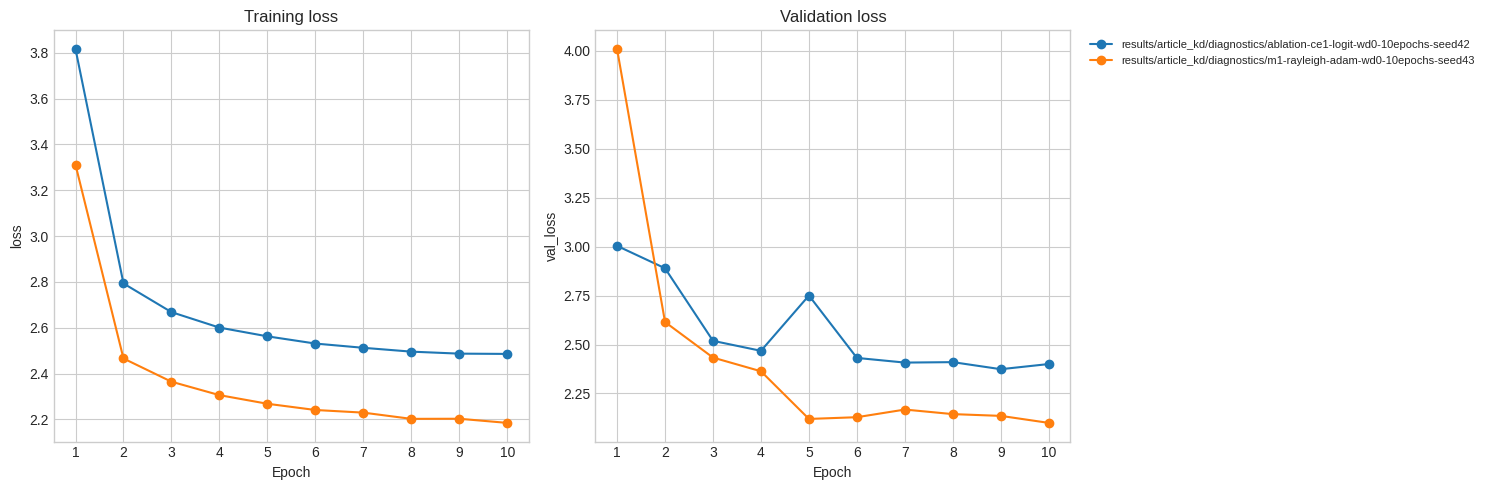

In [6]:
def save_figure(fig, filename):
    if SAVE_DIR is not None:
        output_dir = Path(SAVE_DIR)
        output_dir.mkdir(parents=True, exist_ok=True)
        output = output_dir / filename
        fig.savefig(output, dpi=180, bbox_inches="tight")
        print(f"Saved {output}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=False)
for label, frame in runs.items():
    axes[0].plot(frame["epoch"], frame["loss"], marker="o", label=label)
    axes[1].plot(frame["epoch"], frame["val_loss"], marker="o", label=label)
for axis, title, ylabel in zip(axes, ["Training loss", "Validation loss"], ["loss", "val_loss"]):
    axis.set(title=title, xlabel="Epoch", ylabel=ylabel)
    axis.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
save_figure(fig, "loss_comparison.png")
plt.show()

## Plot all selected metrics

With `METRICS = None`, constant configuration columns (for example a fixed temperature) are omitted automatically. Every run containing a metric is drawn on the same axis.

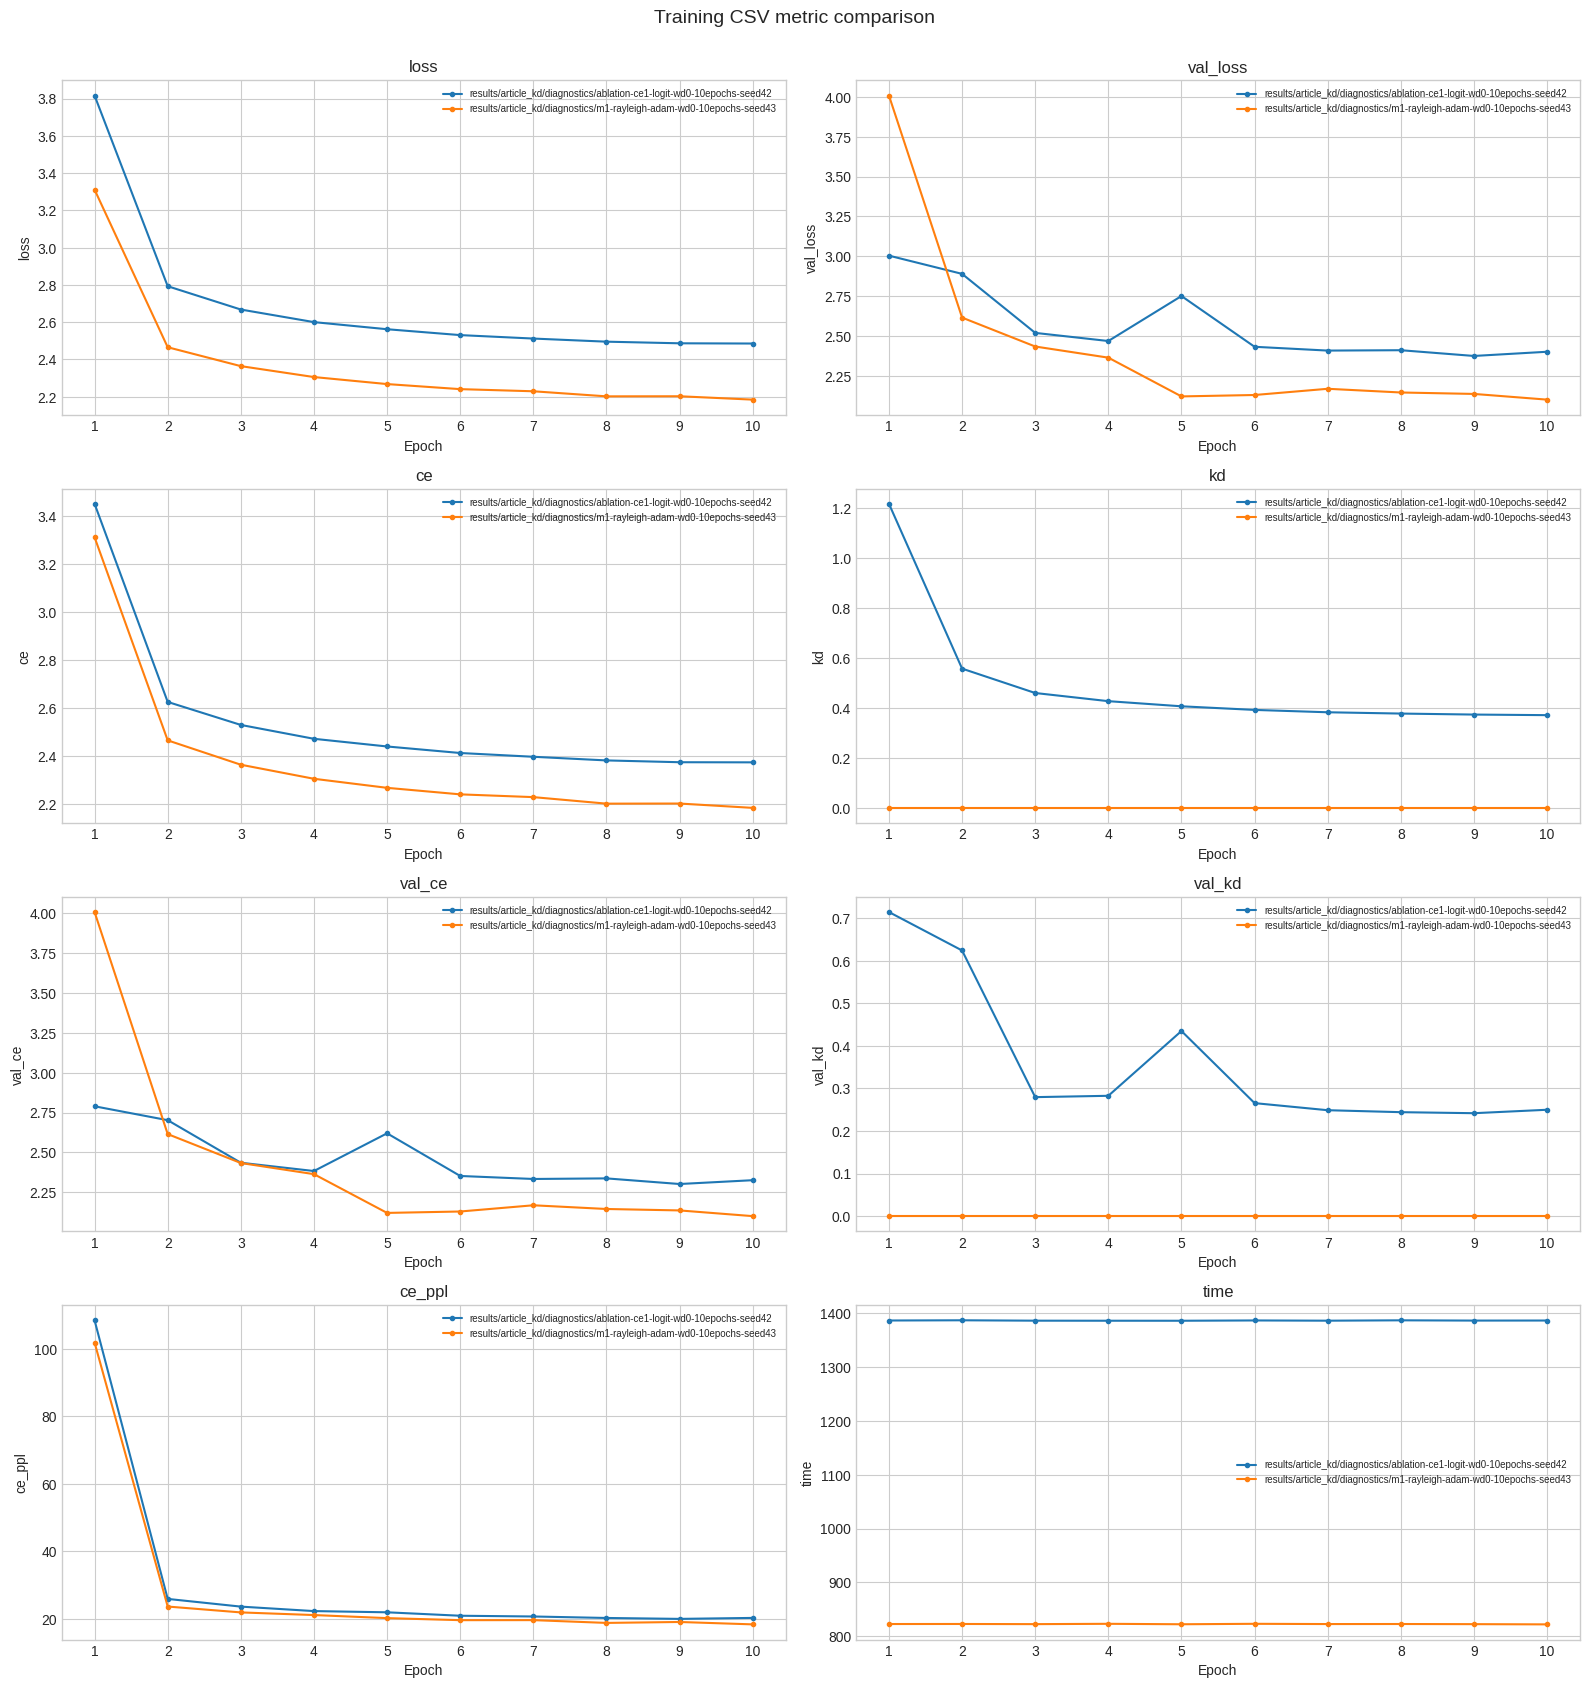

In [ ]:
def varying_numeric_metrics(runs):
    ordered = []
    for frame in runs.values():
        for column in frame.select_dtypes(include=np.number).columns:
            if column != "epoch" and column not in ordered:
                ordered.append(column)
    return [
        column for column in ordered
        if any(column in frame and frame[column].nunique(dropna=True) > 1 for frame in runs.values())
    ]

metrics = varying_numeric_metrics(runs) if METRICS is None else list(METRICS)
available = {column for frame in runs.values() for column in frame.columns}
missing_metrics = [metric for metric in metrics if metric not in available]
if missing_metrics:
    raise KeyError(f"Requested metrics not present in any CSV: {missing_metrics}")

ncols = 2
nrows = math.ceil(len(metrics) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows), squeeze=False)
for axis, metric in zip(axes.flat, metrics):
    plotted = False
    for label, frame in runs.items():
        if metric in frame:
            axis.plot(frame["epoch"], frame[metric], marker="o", markersize=3, label=label)
            plotted = True
    axis.set(title=metric, xlabel="Epoch", ylabel=metric)
    axis.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    if plotted:
        axis.legend(fontsize=7)
for axis in axes.flat[len(metrics):]:
    axis.remove()
fig.suptitle("Training CSV metric comparison", fontsize=14, y=1.002)
fig.tight_layout()
# save_figure(fig, "all_training_metrics.png")
plt.show()

## Optional: compare a metric at each run's best validation epoch

This table is descriptive. Runs with different protocols should not be treated as controlled comparisons merely because their CSVs are plotted together.

In [8]:
best_rows = []
for label, frame in runs.items():
    row = frame.loc[frame["val_loss"].idxmin()].copy()
    row["run"] = label
    best_rows.append(row)
best_epoch_details = pd.DataFrame(best_rows).set_index("run")
display(best_epoch_details)

,epoch,loss,val_loss,ce,kd,tf,val_ce,val_kd,val_tf,ce_ppl,alpha,beta,gamma,temperature,time
run,,,,,,,,,,,,,,,
results/article_kd/diagnostics/ablation-ce1-logit-wd0-10epochs-seed42,9.0,2.486780,2.373960,2.374635,0.373816,0.0,2.301394,0.241886,0.0,19.952368,1.0,0.3,0.0,2.0,1386.144656
results/article_kd/diagnostics/m1-rayleigh-adam-wd0-10epochs-seed43,10.0,2.184534,2.099714,2.184534,0.000000,0.0,2.099714,0.000000,0.0,18.323569,1.0,0.0,0.0,2.0,822.191116
